# Inventory Replenishment Agent
**Group Exercise – Agentic AI in Supply Chain** · SJSU · Fall 2026

This notebook is self-contained: run all cells top to bottom. If `sales.csv`, `inventory.csv` and `params.csv` are not found in `./data/`, the notebook generates them first (so it also runs on a fresh Colab/Binder session).

---
## 1. Design Document

**Agent goal.** Each day, for each SKU, decide *how much to order or whether to wait*, so as to **minimize stockouts and total cost** (holding + stockout + order cost) while hitting the SKU's target service level.

**Inputs (what the agent sees each morning).** On-hand stock (after today's arrivals) · units already on order (pipeline) · EWMA demand forecast built only from *past* sales · running forecast-error estimate · per-SKU parameters: `lead_time_days`, `service_level`, `min_order_qty`, `holding_cost_per_day`, `stockout_cost`, `unit_cost`.

**Outputs.** Either `ORDER q` (a purchase order of *q* units, delivered after the lead time) or `WAIT`, plus a one-line written rationale that goes into the daily agent log.

**Decision rule.**
1. Protection interval `H = lead_time + review_period` (an order placed today can't help until it arrives, and the next chance to order is tomorrow).
2. Safety stock `SS = z(service_level) × σ_err × √H`, where σ_err is the EWMA-tracked one-day forecast error.
3. Inventory position `IP = on_hand + on_order`. Projected stock at the end of the protection interval is `IP − forecast × H`.
4. If projected stock `< SS` → order up to `S = forecast × H + SS`; otherwise wait (waiting avoids holding cost).

**Guardrails / business rules.**
- Orders are never smaller than `min_order_qty`.
- Lead time is built into the projection; the service level drives safety stock.
- **Over-order cap:** inventory position may never exceed `forecast × (H + CAP_EXTRA_DAYS) + SS`. If `min_order_qty` would breach the cap, the agent waits and says why.
- No orders that could not arrive before the horizon ends.
- Trade-off: holding cost (cost of waiting) vs stockout cost (cost of a lost sale) is the reason the agent doesn't simply stock up on everything.

**Metrics.**
- *Stockouts*: units of unmet demand (and number of days with a shortfall).
- *Fill rate* = 1 − unmet units ÷ total demand units.
- *Total cost* = holding + stockout + order cost.
- Also tracked: average inventory and inventory value (working capital).

**Ethics & trust.** Stockouts are broken promises to customers, so the service level is a *reliability commitment*; over-stocking ties up cash and creates waste, so cost control is a *stewardship responsibility*. The agent is deliberately simple, parameterized and transparent: every action is justified in a daily log that a planner can audit and override. It recommends purchase orders; a human owns the budget.

In [1]:
# ---- Imports & configuration --------------------------------------------------
import math
from pathlib import Path
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Adjustable knobs (all parameters of the agent live here or in params.csv)
DATA_DIR          = Path("data")   # where the three CSVs live
ALPHA             = 0.20           # EWMA smoothing factor for the demand level
ERR_ALPHA         = 0.10           # EWMA smoothing factor for forecast-error variance
WARMUP_DAYS       = 14             # history used to initialise forecast + error estimate
REVIEW_PERIOD     = 1              # days between decisions (daily review)
CAP_EXTRA_DAYS    = 5              # over-ordering cap: extra days of demand allowed above target
ORDER_COST_PER_PO = 20.0           # fixed cost per purchase order (assignment allows 0 or a constant)
SERVICE_LEVEL_OVERRIDE = None      # e.g. 0.99 to override every SKU's service_level
SEED              = 42

## 2. Data (generate if missing → load → aggregate)

In [2]:
def generate_data(data_dir: Path, seed: int = SEED, n_days: int = 90, start: str = "2026-08-01"):
    # Create synthetic sales.csv, inventory.csv, params.csv (3 SKUs, 90 days).
    rng = np.random.default_rng(seed)
    data_dir.mkdir(parents=True, exist_ok=True)
    dates = pd.date_range(start, periods=n_days, freq="D")

    # base demand, trend per day, weekday-amplitude per SKU
    profile = {"SKU_A": (40, 0.00, 0.25), "SKU_B": (25, 0.20, 0.35), "SKU_C": (12, 0.00, 0.40)}
    rows = []
    for sku, (base, trend, amp) in profile.items():
        weekly = 1 + amp * np.sin(2 * np.pi * dates.dayofweek / 7)
        promo = np.where(rng.random(n_days) < 0.05, 1.8, 1.0)         # occasional promo spike
        mean = (base + trend * np.arange(n_days)) * weekly * promo
        qty = rng.poisson(mean)
        for d, q in zip(dates, qty):
            if q == 0:
                continue                                              # no row on zero-sale days
            k = rng.integers(1, 4)                                    # split into 1-3 order lines
            for part in rng.multinomial(q, np.ones(k) / k):
                if part > 0:
                    rows.append((d.date().isoformat(), sku, int(part)))
    pd.DataFrame(rows, columns=["date", "sku", "qty_sold"]).to_csv(data_dir / "sales.csv", index=False)

    pd.DataFrame({"sku": ["SKU_A", "SKU_B", "SKU_C"], "opening_stock": [120, 150, 100]}) \
      .to_csv(data_dir / "inventory.csv", index=False)

    pd.DataFrame({
        "sku": ["SKU_A", "SKU_B", "SKU_C"],
        "unit_cost": [8.0, 15.0, 40.0],
        "holding_cost_per_day": [0.10, 0.20, 0.50],
        "stockout_cost": [4.0, 9.0, 25.0],
        "lead_time_days": [3, 5, 7],
        "min_order_qty": [60, 50, 30],
        "service_level": [0.95, 0.95, 0.90],
    }).to_csv(data_dir / "params.csv", index=False)

if not all((DATA_DIR / f).exists() for f in ["sales.csv", "inventory.csv", "params.csv"]):
    generate_data(DATA_DIR)
    print("Generated CSVs in", DATA_DIR.resolve())

sales     = pd.read_csv(DATA_DIR / "sales.csv", parse_dates=["date"])
inventory = pd.read_csv(DATA_DIR / "inventory.csv").set_index("sku")
params    = pd.read_csv(DATA_DIR / "params.csv").set_index("sku")

# Aggregate: many order lines -> one demand number per SKU per day; fill missing days with 0
demand = (sales.groupby(["date", "sku"])["qty_sold"].sum().unstack("sku")
               .reindex(pd.date_range(sales["date"].min(), sales["date"].max(), freq="D"))
               .fillna(0).astype(int))
demand.index.name = "date"
SKUS = list(params.index)

print(f"sales.csv: {len(sales)} rows → daily demand table {demand.shape[0]} days × {demand.shape[1]} SKUs")
display(inventory); display(params); display(demand.head(8)); display(demand.describe().loc[["mean", "std", "min", "max"]].round(1))

sales.csv: 544 rows → daily demand table 90 days × 3 SKUs


,opening_stock
sku,
SKU_A,120
SKU_B,150
SKU_C,100


,unit_cost,holding_cost_per_day,stockout_cost,lead_time_days,min_order_qty,service_level
sku,,,,,,
SKU_A,8.0,0.1,4.0,3,60,0.95
SKU_B,15.0,0.2,9.0,5,50,0.95
SKU_C,40.0,0.5,25.0,7,30,0.90


sku,SKU_A,SKU_B,SKU_C
date,,,
2026-08-01,24,17,4
2026-08-02,31,18,5
2026-08-03,36,17,13
2026-08-04,45,31,23
2026-08-05,61,27,20
2026-08-06,50,39,16
2026-08-07,35,18,13
2026-08-08,22,17,12


sku,SKU_A,SKU_B,SKU_C
mean,40.7,34.4,11.5
std,12.4,14.1,4.8
min,18.0,17.0,1.0
max,89.0,108.0,26.0


## 3. Forecast, safety stock & the agent

In [3]:
class EWMAForecaster:
    # Exponentially weighted moving average of demand + EWMA of squared forecast error.
    # The forecast for day t uses only sales up to day t-1 (no look-ahead); update() is called each night.
    def __init__(self, warmup: pd.Series, alpha: float = ALPHA, err_alpha: float = ERR_ALPHA):
        self.alpha, self.err_alpha = alpha, err_alpha
        self.level = float(warmup.iloc[:7].mean())          # initial level
        sq = []
        for y in warmup.iloc[7:]:                           # learn error scale from warm-up history
            sq.append((y - self.level) ** 2)
            self.level += alpha * (y - self.level)
        self.var = float(np.mean(sq)) if sq else float(warmup.var())

    @property
    def forecast(self) -> float:                            # expected demand per day
        return self.level

    @property
    def sigma(self) -> float:                               # std-dev of 1-day forecast error
        return math.sqrt(self.var)

    def update(self, actual: float):                        # daily update with the day's actual demand
        err = actual - self.level
        self.var = self.err_alpha * err ** 2 + (1 - self.err_alpha) * self.var
        self.level += self.alpha * err


def safety_stock(sigma_1day: float, horizon_days: int, service_level: float) -> float:
    # SS = z * sigma * sqrt(H); z from the target service level
    return NormalDist().inv_cdf(service_level) * sigma_1day * math.sqrt(horizon_days)


class ReplenishmentAgent:
    # Daily decision: ORDER q or WAIT, with a written rationale.
    def __init__(self, p, warmup, alpha=ALPHA, err_alpha=ERR_ALPHA,
                 review_period=REVIEW_PERIOD, cap_extra_days=CAP_EXTRA_DAYS):
        self.p, self.R, self.cap_extra = p, review_period, cap_extra_days
        self.fc = EWMAForecaster(warmup, alpha, err_alpha)

    def decide(self, on_hand: float, on_order: float) -> dict:
        p = self.p
        L, moq = int(p["lead_time_days"]), int(p["min_order_qty"])
        H = L + self.R                                       # protection interval
        f = self.fc.forecast
        ss = safety_stock(self.fc.sigma, H, p["service_level"])
        ip = on_hand + on_order                              # inventory position
        exp_demand = f * H
        projected = ip - exp_demand                          # expected stock when a new order could land
        target = exp_demand + ss                             # order-up-to level S
        cap = f * (H + self.cap_extra) + ss                  # guardrail against over-ordering
        info = dict(forecast=f, safety_stock=ss, inv_position=ip, projected=projected)

        if projected >= ss:
            return dict(action="WAIT", qty=0, **info,
                        rationale=f"projected {projected:.0f} ≥ SS {ss:.0f} over next {H}d → wait (saves holding cost)")
        qty = max(math.ceil(target - ip), moq)               # respect min_order_qty
        if ip + qty > cap:                                   # don't over-order
            qty = int(cap - ip)
            if qty < moq:
                return dict(action="WAIT", qty=0, **info,
                            rationale=f"projected {projected:.0f} < SS {ss:.0f} but min order {moq} would exceed cap {cap:.0f} → wait")
        why = " (raised to min_order_qty)" if qty == moq and math.ceil(target - ip) < moq else ""
        return dict(action="ORDER", qty=int(qty), **info,
                    rationale=f"projected {projected:.0f} < SS {ss:.0f} over next {H}d → order {qty}{why} (order-up-to S={target:.0f})")

    def observe(self, actual_demand: float):
        self.fc.update(actual_demand)

## 4. Baseline strategy (fixed reorder rule, no forecast)

In [4]:
class FixedReorderBaseline:
    # Simple (s, Q) rule with NO forecasting and NO service-level logic:
    #   reorder point s = warm-up mean daily demand x (lead time + 2 days), fixed order quantity Q = 10 days of mean demand.
    def __init__(self, p, warmup, **_):
        mean = float(warmup.mean())
        self.p = p
        self.rop = mean * (int(p["lead_time_days"]) + 2)
        self.q = max(int(p["min_order_qty"]), math.ceil(mean * 10))

    def decide(self, on_hand, on_order):
        ip = on_hand + on_order
        if ip <= self.rop:
            return dict(action="ORDER", qty=self.q, forecast=np.nan, safety_stock=np.nan, inv_position=ip, projected=np.nan,
                        rationale=f"position {ip:.0f} ≤ fixed ROP {self.rop:.0f} → order fixed Q={self.q}")
        return dict(action="WAIT", qty=0, forecast=np.nan, safety_stock=np.nan, inv_position=ip, projected=np.nan,
                    rationale=f"position {ip:.0f} > fixed ROP {self.rop:.0f} → wait")

    def observe(self, actual_demand):
        pass

## 5. Day-by-day simulation (orders arrive after the lead time)

In [5]:
def simulate_sku(sku, daily_demand: pd.Series, opening_stock: int, p, policy) -> pd.DataFrame:
    # Replays history day by day. Order of events each day:
    #   1) receive POs due today  2) policy decides  3) demand is served (unmet demand is lost)
    #   4) costs accrue on end-of-day stock  5) policy learns today's actual demand
    L, n = int(p["lead_time_days"]), len(daily_demand)
    on_hand, pipeline, rows = float(opening_stock), {}, []
    for i, (date, d) in enumerate(daily_demand.items()):
        arrivals = pipeline.pop(i, 0)
        on_hand += arrivals
        on_order = sum(pipeline.values())
        start_stock = on_hand

        dec = policy.decide(on_hand, on_order)
        if dec["qty"] > 0 and i + L >= n:                    # guardrail: PO couldn't arrive inside the horizon
            dec.update(action="WAIT", qty=0, rationale=dec["rationale"] + " [suppressed: would arrive after horizon]")
        if dec["qty"] > 0:
            pipeline[i + L] = pipeline.get(i + L, 0) + dec["qty"]

        sales = min(on_hand, d)
        lost = d - sales
        on_hand -= sales
        rows.append(dict(date=date, sku=sku, arrivals=arrivals, start_stock=start_stock, on_order=on_order,
                         forecast=dec["forecast"], safety_stock=dec["safety_stock"], inv_position=dec["inv_position"],
                         action=dec["action"], order_qty=dec["qty"], demand=d, sales=sales, lost=lost, end_stock=on_hand,
                         holding_cost=p["holding_cost_per_day"] * on_hand,
                         stockout_cost=p["stockout_cost"] * lost,
                         order_cost=ORDER_COST_PER_PO if dec["qty"] > 0 else 0.0,
                         rationale=dec["rationale"]))
        policy.observe(d)
    return pd.DataFrame(rows)


def run_policy(policy_cls, alpha=ALPHA, service_level=SERVICE_LEVEL_OVERRIDE, **kw) -> pd.DataFrame:
    # Run a policy for every SKU on the post-warm-up window; returns the combined daily log.
    warm, sim = demand.iloc[:WARMUP_DAYS], demand.iloc[WARMUP_DAYS:]
    logs = []
    for sku in SKUS:
        p = params.loc[sku].copy()
        if service_level is not None:
            p["service_level"] = service_level
        policy = policy_cls(p, warm[sku], alpha=alpha, **kw)
        logs.append(simulate_sku(sku, sim[sku], inventory.loc[sku, "opening_stock"], p, policy))
    return pd.concat(logs, ignore_index=True)


def kpis(log: pd.DataFrame) -> pd.DataFrame:
    # Per-SKU and TOTAL metrics: stockouts, fill rate, costs, working capital.
    log = log.assign(inv_value=log["end_stock"] * log["sku"].map(params["unit_cost"]))
    g = log.groupby("sku")
    out = pd.DataFrame({
        "demand_units": g["demand"].sum(),
        "stockout_units": g["lost"].sum(),
        "stockout_days": g["lost"].apply(lambda s: int((s > 0).sum())),
        "orders_placed": g["order_cost"].apply(lambda s: int((s > 0).sum())),
        "avg_inventory": g["end_stock"].mean(),
        "avg_inv_value$": g["inv_value"].mean(),
        "holding_cost": g["holding_cost"].sum(),
        "stockout_cost": g["stockout_cost"].sum(),
        "order_cost": g["order_cost"].sum(),
    })
    out["fill_rate"] = 1 - out["stockout_units"] / out["demand_units"]
    out["total_cost"] = out["holding_cost"] + out["stockout_cost"] + out["order_cost"]
    tot = out.sum(numeric_only=True)
    tot["fill_rate"] = 1 - tot["stockout_units"] / tot["demand_units"]
    out.loc["TOTAL"] = tot
    return out

## 6. Run the agent and print the daily agent log

In [6]:
agent_log = run_policy(ReplenishmentAgent)

# --- Daily agent log: one line per SKU per day, with rationale ---
print(f"AGENT LOG  (alpha={ALPHA}, review={REVIEW_PERIOD}d, warm-up={WARMUP_DAYS}d, simulated days={agent_log['date'].nunique()})\n")
for _, r in agent_log.sort_values(["date", "sku"]).iterrows():
    arr = f"+{r.arrivals:.0f} arrived" if r.arrivals else "no arrival"
    print(f"{r.date:%Y-%m-%d} {r.sku} | stock {r.start_stock:4.0f} ({arr:>12}) on-order {r.on_order:4.0f} | "
          f"F={r.forecast:5.1f}/d SS={r.safety_stock:5.1f} | {r.action:5} {r.order_qty:4d} | {r.rationale} "
          f"|| demand {r.demand:3d} sold {r.sales:3.0f} lost {r.lost:3.0f} end {r.end_stock:4.0f}")

AGENT LOG  (alpha=0.2, review=1d, warm-up=14d, simulated days=76)

2026-08-15 SKU_A | stock  120 (  no arrival) on-order    0 | F= 38.7/d SS= 39.9 | ORDER   75 | projected -35 < SS 40 over next 4d → order 75 (order-up-to S=195) || demand  27 sold  27 lost   0 end   93
2026-08-15 SKU_B | stock  150 (  no arrival) on-order    0 | F= 25.9/d SS= 36.6 | ORDER   50 | projected -6 < SS 37 over next 6d → order 50 (raised to min_order_qty) (order-up-to S=192) || demand  23 sold  23 lost   0 end  127
2026-08-15 SKU_C | stock  100 (  no arrival) on-order    0 | F= 11.3/d SS= 12.4 | ORDER   30 | projected 10 < SS 12 over next 8d → order 30 (raised to min_order_qty) (order-up-to S=103) || demand  11 sold  11 lost   0 end   89
2026-08-16 SKU_A | stock   93 (  no arrival) on-order   75 | F= 36.4/d SS= 39.7 | ORDER   60 | projected 23 < SS 40 over next 4d → order 60 (raised to min_order_qty) (order-up-to S=185) || demand  24 sold  24 lost   0 end   69
2026-08-16 SKU_B | stock  127 (  no arrival) on-or

## 7. Baseline run and evaluation

In [7]:
base_log = run_policy(FixedReorderBaseline)

k_agent, k_base = kpis(agent_log), kpis(base_log)
cols = ["demand_units", "stockout_units", "stockout_days", "fill_rate", "holding_cost", "stockout_cost",
        "order_cost", "total_cost", "orders_placed", "avg_inventory", "avg_inv_value$"]
print("=== AGENT (EWMA forecast + service-level safety stock) ===");  display(k_agent[cols].round(3))
print("=== BASELINE (fixed reorder point, fixed Q, no forecast) ==="); display(k_base[cols].round(3))

cmp = pd.DataFrame({"Baseline": k_base.loc["TOTAL", cols], "Agent": k_agent.loc["TOTAL", cols]})
cmp["Change (Agent vs Baseline)"] = cmp["Agent"] - cmp["Baseline"]
cmp["% change"] = 100 * cmp["Change (Agent vs Baseline)"] / cmp["Baseline"].replace(0, np.nan)
print("=== TOTAL comparison ==="); display(cmp.round(3))

imp = 100 * (k_base.loc["TOTAL", "total_cost"] - k_agent.loc["TOTAL", "total_cost"]) / k_base.loc["TOTAL", "total_cost"]
print(f"Total cost: baseline ${k_base.loc['TOTAL','total_cost']:,.0f} vs agent ${k_agent.loc['TOTAL','total_cost']:,.0f} "
      f"({abs(imp):.1f}% {'lower' if imp >= 0 else 'higher'} for the agent).  Fill rate: {k_base.loc['TOTAL','fill_rate']:.1%} → {k_agent.loc['TOTAL','fill_rate']:.1%}.")

=== AGENT (EWMA forecast + service-level safety stock) ===


,demand_units,stockout_units,stockout_days,fill_rate,holding_cost,stockout_cost,order_cost,total_cost,orders_placed,avg_inventory,avg_inv_value$
sku,,,,,,,,,,,
SKU_A,3123.0,35.0,4.0,0.989,525.8,140.0,980.0,1645.8,49.0,69.184,553.474
SKU_B,2750.0,55.0,4.0,0.980,1004.0,495.0,880.0,2379.0,44.0,66.053,990.789
SKU_C,865.0,9.0,1.0,0.990,1392.0,225.0,520.0,2137.0,26.0,36.632,1465.263
TOTAL,6738.0,99.0,9.0,0.985,2921.8,860.0,2380.0,6161.8,119.0,171.868,3009.526


=== BASELINE (fixed reorder point, fixed Q, no forecast) ===


,demand_units,stockout_units,stockout_days,fill_rate,holding_cost,stockout_cost,order_cost,total_cost,orders_placed,avg_inventory,avg_inv_value$
sku,,,,,,,,,,,
SKU_A,3123.0,21.0,1.0,0.993,1629.7,84.0,160.0,1873.7,8.0,214.434,1715.474
SKU_B,2750.0,249.0,10.0,0.909,1434.2,2241.0,200.0,3875.2,10.0,94.355,1415.329
SKU_C,865.0,3.0,1.0,0.997,2893.5,75.0,140.0,3108.5,7.0,76.145,3045.789
TOTAL,6738.0,273.0,12.0,0.959,5957.4,2400.0,500.0,8857.4,25.0,384.934,6176.592


=== TOTAL comparison ===


,Baseline,Agent,Change (Agent vs Baseline),% change
demand_units,6738.000,6738.000,0.000,0.000
stockout_units,273.000,99.000,-174.000,-63.736
stockout_days,12.000,9.000,-3.000,-25.000
fill_rate,0.959,0.985,0.026,2.691
holding_cost,5957.400,2921.800,-3035.600,-50.955
stockout_cost,2400.000,860.000,-1540.000,-64.167
order_cost,500.000,2380.000,1880.000,376.000
total_cost,8857.400,6161.800,-2695.600,-30.433
orders_placed,25.000,119.000,94.000,376.000
avg_inventory,384.934,171.868,-213.066,-55.351


Total cost: baseline $8,857 vs agent $6,162 (30.4% lower for the agent).  Fill rate: 95.9% → 98.5%.


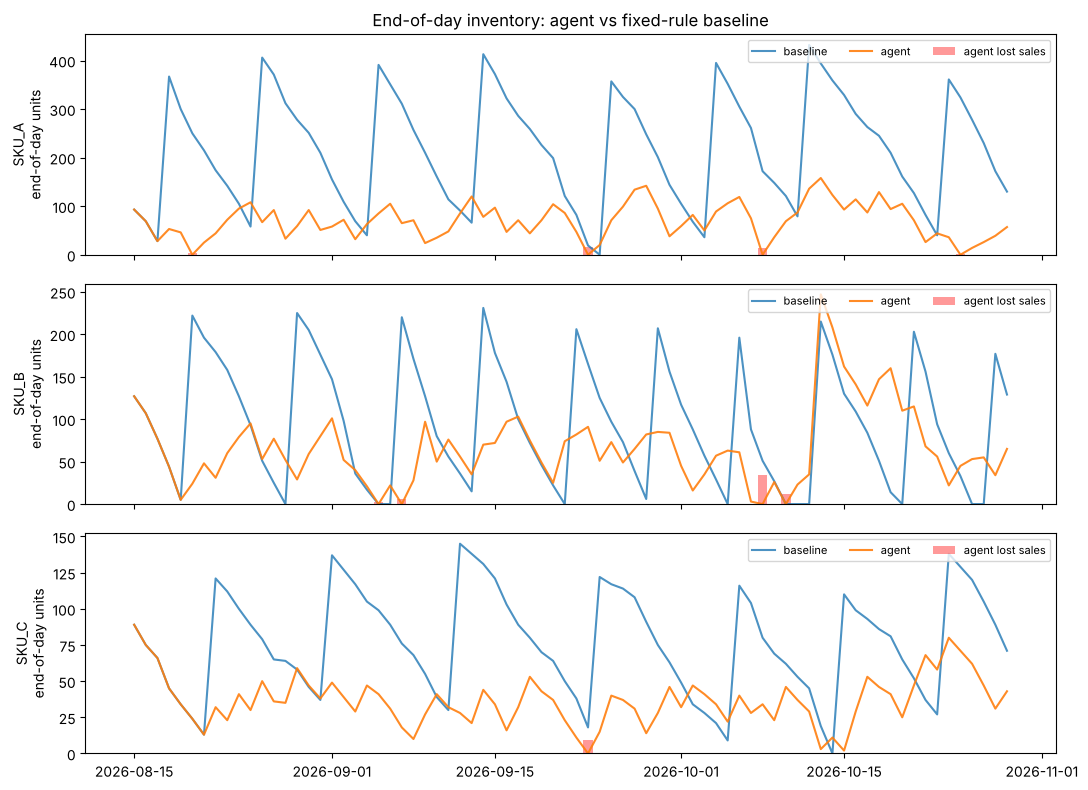

In [8]:
fig, axes = plt.subplots(len(SKUS), 1, figsize=(11, 8), sharex=True)
for ax, sku in zip(axes, SKUS):
    a, b = agent_log[agent_log.sku == sku], base_log[base_log.sku == sku]
    ax.plot(b["date"], b["end_stock"], label="baseline", alpha=.8)
    ax.plot(a["date"], a["end_stock"], label="agent", alpha=.9)
    ax.bar(a["date"], a["lost"], color="red", alpha=.4, label="agent lost sales")
    ax.set_ylabel(f"{sku}\nend-of-day units"); ax.legend(loc="upper right", ncol=3, fontsize=8)
axes[0].set_title("End-of-day inventory: agent vs fixed-rule baseline")
plt.tight_layout(); plt.savefig("inventory_comparison.png", dpi=120); plt.show()

## 8. Sensitivity: the inventory ↔ service trade-off

Service-level sweep (all SKUs, agent):


,service_level,fill_rate,stockout_units,avg_inventory,holding_cost,stockout_cost,total_cost
0,0.80,0.961,266.0,134.263,2402.7,2262.0,6984.7
1,0.85,0.968,216.0,141.895,2501.3,1573.0,6414.3
2,0.90,0.973,181.0,156.395,2745.5,1308.0,6393.5
3,0.95,0.986,94.0,175.000,3040.8,735.0,6155.8
4,0.98,0.991,58.0,202.697,3522.2,487.0,6369.2
5,0.99,0.994,38.0,216.329,3734.8,342.0,6436.8


EWMA alpha sweep (agent, per-SKU service levels from params.csv):


,alpha,fill_rate,stockout_units,avg_inventory,total_cost
0,0.05,0.989,74.0,152.118,5819.0
1,0.10,0.988,84.0,162.276,5976.3
2,0.20,0.985,99.0,171.868,6161.8
3,0.30,0.984,106.0,178.882,6264.7
4,0.50,0.974,178.0,208.724,7171.9


Fixed order-cost sweep (agent vs baseline, same decisions, re-priced):


,order_cost_per_PO,agent_total,baseline_total,agent_saving_pct
0,0,3781.8,8357.4,54.7
1,20,6161.8,8857.4,30.4
2,50,9731.8,9607.4,-1.3
3,100,15681.8,10857.4,-44.4
4,200,27581.8,13357.4,-106.5


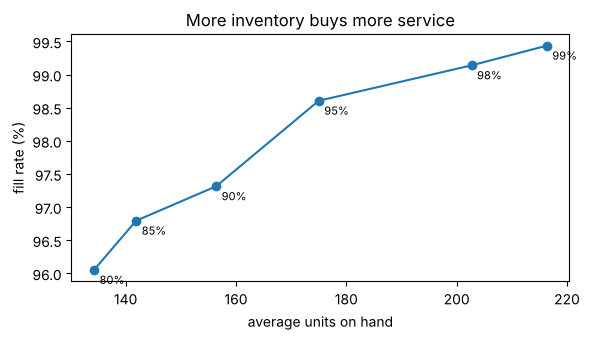

In [9]:
rows = []
for sl in [0.80, 0.85, 0.90, 0.95, 0.98, 0.99]:
    k = kpis(run_policy(ReplenishmentAgent, service_level=sl)).loc["TOTAL"]
    rows.append(dict(service_level=sl, fill_rate=k.fill_rate, stockout_units=k.stockout_units, avg_inventory=k.avg_inventory,
                     holding_cost=k.holding_cost, stockout_cost=k.stockout_cost, total_cost=k.total_cost))
sens_sl = pd.DataFrame(rows)
print("Service-level sweep (all SKUs, agent):"); display(sens_sl.round(3))

rows = []
for a in [0.05, 0.10, 0.20, 0.30, 0.50]:
    k = kpis(run_policy(ReplenishmentAgent, alpha=a)).loc["TOTAL"]
    rows.append(dict(alpha=a, fill_rate=k.fill_rate, stockout_units=k.stockout_units, avg_inventory=k.avg_inventory, total_cost=k.total_cost))
sens_a = pd.DataFrame(rows)
print("EWMA alpha sweep (agent, per-SKU service levels from params.csv):"); display(sens_a.round(3))

# Order-cost sensitivity: the agent places many small POs, so its edge depends on the fixed cost per PO.
rows = []
for K in [0, 20, 50, 100, 200]:
    ta = k_agent.loc["TOTAL"]; tb = k_base.loc["TOTAL"]
    ca = ta.total_cost - ta.order_cost + ta.orders_placed * K
    cb = tb.total_cost - tb.order_cost + tb.orders_placed * K
    rows.append(dict(order_cost_per_PO=K, agent_total=ca, baseline_total=cb, agent_saving_pct=100 * (cb - ca) / cb))
print("Fixed order-cost sweep (agent vs baseline, same decisions, re-priced):"); display(pd.DataFrame(rows).round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(sens_sl["avg_inventory"], sens_sl["fill_rate"] * 100, "o-")
for _, r in sens_sl.iterrows():
    ax.annotate(f"{r.service_level:.0%}", (r.avg_inventory, r.fill_rate * 100), textcoords="offset points", xytext=(4, -10), fontsize=8)
ax.set_xlabel("average units on hand"); ax.set_ylabel("fill rate (%)"); ax.set_title("More inventory buys more service")
plt.tight_layout(); plt.savefig("tradeoff_curve.png", dpi=120); plt.show()

## 9. Trade-off reflection

**Inventory vs service.** Every extra unit of safety stock buys service but costs holding money. In the service-level sweep above, moving the target from 80% to 99% raises the fill rate from about 96% to 99%, but average inventory grows by roughly 60% (≈134 → ≈216 units). Total cost is lowest around the 90–95% targets: below that, stockout penalties dominate; above that, holding cost grows faster than the stockout cost it removes. This is why `service_level` is a business decision (how costly is a disappointed customer vs tied-up cash?), not a technical default. Per-SKU targets matter too: SKU_C is expensive to hold and has the lowest target.

**Agent vs baseline.** With a $20 fixed cost per PO, the agent cut total cost by about 30% (≈$6.2k vs ≈$8.9k), cut stockout units by about 64% and held about 55% less inventory, mainly because it forecasts, scales safety stock to each SKU's actual error and lead time, and adapts to SKU_B's upward trend, which the static baseline missed (fill rate ≈91% on SKU_B).

**Honest limitation.** The agent's advantage depends on order cost. It checks daily and often orders the minimum quantity (119 POs vs 25 for the baseline), so as the fixed cost per PO rises its edge shrinks, breaking even near $50/PO in the table above and losing beyond that. If POs are expensive, the policy should batch orders (longer review period or a larger order quantity such as EOQ), accepting more inventory for fewer orders. The EWMA also used a single flat forecast and ignored the weekly pattern, which is why safety stock is fairly large; a day-of-week adjustment would be a natural improvement. Results come from one 76-day synthetic replay, so treat the percentages as illustrative rather than precise.

## 10. Scaling Note (production deployment)

**Cloud deployment.** Package the agent as a Docker container and run it as a scheduled job (e.g., cron / Cloud Scheduler → Cloud Run job or AWS EventBridge → ECS/Fargate) every night after the sales feed closes. Inputs come from a warehouse/S3 bucket instead of local CSVs; outputs (recommended POs + the daily log) are written back to a table and sent to a planner for approval.

**Monitoring.** Track per-SKU fill rate and stockout days against the service-level target, with an alert when a rolling 7-day fill rate drops below target. Track forecast error (MAPE / bias) and σ_err over time; alert on drift or sudden jumps (e.g., promotion or supplier change). Keep the daily log in a searchable store for audit.

**Reliability.** Retry data pulls with exponential backoff; validate schemas; handle missing days (treat as 0 only if the store was open, otherwise carry the forecast forward), duplicate rows and negative quantities. If the job fails, fall back to the last approved reorder points rather than doing nothing. Runs are idempotent (keyed by date) so reruns don't double-order.

**Cost controls.** Hard inventory cap per SKU (already implemented as `CAP_EXTRA_DAYS`), a daily/weekly PO spend budget and working-capital tracker (inventory units × `unit_cost`) with human approval above a threshold, and a monthly review of holding vs stockout cost parameters.